In [4]:
import torch
import os
import glob
from PIL import Image
import numpy as np
from torch.utils.data import Dataset, DataLoader, random_split
import matplotlib.pyplot as plt
from tqdm import tqdm

# --- IMPOSTAZIONE DEL DEVICE (GPU o CPU) ---
# Questa cella definisce il device una volta per tutte.
# Tutte le altre parti del codice useranno questa variabile.
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Device in uso: {device}")


print(f"Current working directory: {os.getcwd()}")

COLAB = False;
if COLAB:
    # Montiamo Google Drive
    from google.colab import drive
    drive.mount('/content/drive')

    # Definiamo il percorso principale
    DATASET_PATH = "/content/drive/MyDrive/Uni/Magistrale/colab/1/ML/Project/training/train"
else:
    DATASET_PATH = "../../dataset/training/train"

# Se si vuole eseguire tutto solo nel main
EXECUTE_MAIN = False;
NUM_WORKERS = 0

Device in uso: cpu
Current working directory: c:\Users\Altair\Documents\GitHub\autoencoder-onboard-segmentation\notebooks\1 - Bilanciamento


In [5]:
# --- DEFINIZIONE DELLA CLASSE DATASET ---
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset

class SegmentationDataset(Dataset):
    """
    Versione definitiva e semplificata del Dataset.
    Legge le immagini e le maschere che contengono già gli ID di classe.
    """
    def __init__(self, sample_dirs, transform=None):
        self.sample_dirs = sample_dirs
        self.transform = transform

    def __len__(self):
        return len(self.sample_dirs)

    def __getitem__(self, idx):
        sample_dir = self.sample_dirs[idx]

        img_path = os.path.join(sample_dir, 'rgb.jpg')
        mask_path = os.path.join(sample_dir, 'labels.png')

        # Carichiamo l'immagine RGB e la maschera
        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path) # È già in scala di grigi con indici 0-8

        # Convertiamo in array NumPy
        # Normalizziamo l'immagine a [0, 1] per la stabilità del training
        image_np = np.array(image, dtype=np.float32) / 255.0
        # Le maschere contengono ID, quindi usiamo un tipo intero
        mask_np = np.array(mask, dtype=np.int64)

        if self.transform:
            # Qui applicheremo la data augmentation nelle fasi successive
            pass

        # Convertiamo in tensori PyTorch
        # Immagine -> [C, H, W]
        image_tensor = torch.from_numpy(image_np).permute(2, 0, 1)
        # Maschera -> [H, W] (la loss CrossEntropy vuole questo formato)
        mask_tensor = torch.from_numpy(mask_np)

        return image_tensor, mask_tensor

Trovati 931 campioni totali validi.


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:13<00:00,  1.15it/s]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


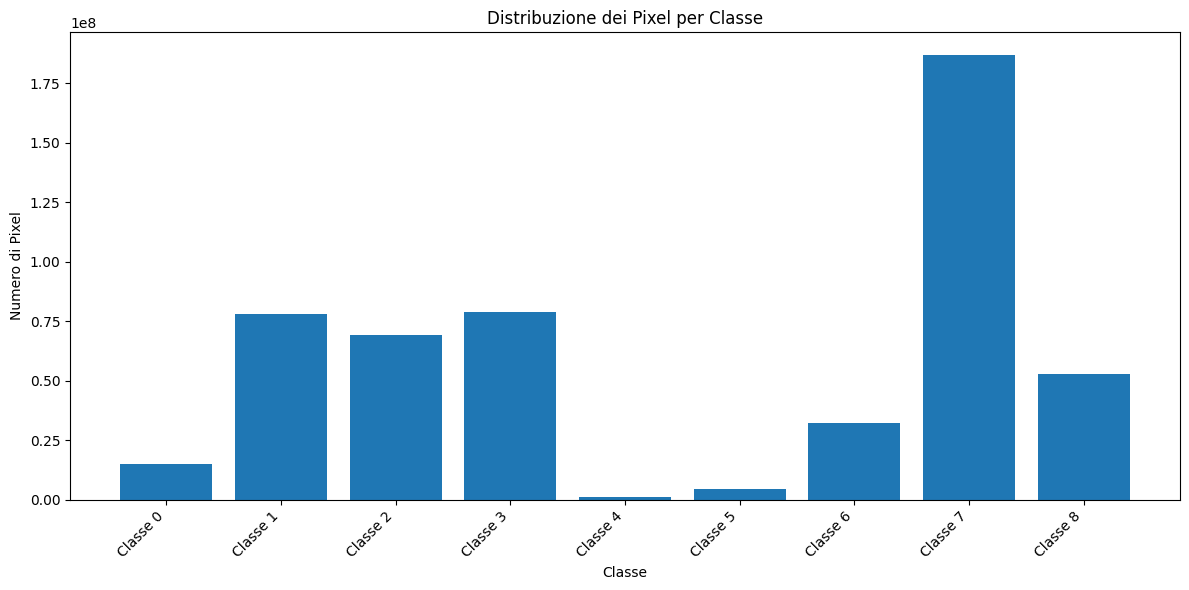

In [6]:
def calculate_class_distribution_gpu(dataset, device):
  """
  Calcola il numero di pixel per ogni classe, usando la GPU se disponibile.
  """
  num_classes = 9 # Da 0 a 8

  class_counts = torch.zeros(num_classes, dtype=torch.int64, device=device)

  loader = DataLoader(dataset, batch_size=64, shuffle=False, num_workers=NUM_WORKERS)

  for _, masks_batch in tqdm(loader, desc="Analisi distribuzione classi (GPU)"):
    masks_batch = masks_batch.to(device)

    for i in range(masks_batch.shape[0]):
      mask = masks_batch[i]
      class_counts += torch.bincount(mask.flatten(), minlength=num_classes)

  # sulla CPU per NumPy e Matplotlib
  return class_counts.cpu()


def distribution_analysis(full_dataset, class_names):
  # Calcoliamo la distribuzione
  distribution = calculate_class_distribution_gpu(full_dataset, device)

  # Stampiamo e visualizziamo i risultati
  total_pixels = distribution.sum()
  print("\nDistribuzione delle classi nel dataset:")
  for i, count in enumerate(distribution):
    percentage = 100 * count.float() / total_pixels
    print(f"- Classe '{class_names[i]}' ({i}): {count} pixel ({percentage:.2f}%)")

  plt.figure(figsize=(12, 6))
  plt.bar(class_names, distribution.numpy())
  plt.xlabel("Classe")
  plt.ylabel("Numero di Pixel")
  plt.title("Distribuzione dei Pixel per Classe")
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()


if not EXECUTE_MAIN:
  # Creiamo un dataset con tutti i campioni ...
  all_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
  # ... senza __MACOSX
  all_sample_dirs = [d for d in all_sample_dirs if not os.path.basename(d).startswith('__')]
  print(f"Trovati {len(all_sample_dirs)} campioni totali validi.")

  full_dataset = SegmentationDataset(sample_dirs=all_sample_dirs)

  class_names = []
  for idx in range(9):
    class_names.append(f"Classe {idx}")

  distribution_analysis(full_dataset, class_names)

In [7]:
import torch
from tqdm import tqdm
import os

def get_representative_images_per_class(dataset, num_classes, class_names, top_n=5):
    """
    Analizza il dataset per trovare le 'top_n' immagini più rappresentative per ogni classe.

    Args:
        dataset (Dataset): L'istanza del dataset completo.
        num_classes (int): Il numero di classi totali.
        class_names (list): La lista dei nomi delle classi.
        top_n (int): Il numero di immagini da mostrare per ogni classe.
    """
    print(f"Inizio analisi per trovare le {top_n} immagini più rappresentative per classe...")

    class_images = [[] for _ in range(num_classes)]

    for i in tqdm(range(len(dataset)), desc="Analisi Immagini"):
        _, mask = dataset[i]
        total_pixels_in_mask = mask.numel()
        if total_pixels_in_mask == 0:
            continue
        counts = torch.bincount(mask.flatten(), minlength=num_classes)
        for class_id in range(num_classes):
            if counts[class_id] > 0:
                percentage = 100.0 * counts[class_id] / total_pixels_in_mask
                sample_path = dataset.sample_dirs[i]
                class_images[class_id].append((percentage, sample_path))

    print("\nAnalisi completata. Ordino e stampo i risultati...")

    # Ordinamento e Stampa
    for class_id in range(num_classes):
        print("-" * 50)
        print(f"CLASSE: {class_names[class_id].upper()} ({class_id})")
        print("-" * 50)

        sorted_images = sorted(class_images[class_id], key=lambda x: x[0], reverse=True)

        if not sorted_images:
            print("Nessuna immagine trovata per questa classe.")
            continue

        # Stampa solo i primi 'top_n' elementi
        for idx, (percentage, path) in enumerate(sorted_images[:top_n]):
            print(f"{idx + 1}. {os.path.basename(path)} (presenza: {percentage:.2f}%)")



print("--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---")
get_representative_images_per_class(full_dataset, num_classes=9, class_names=class_names, top_n=1)



--- STAMPA SOLO LA MIGLIORE IMMAGINE PER CLASSE ---
Inizio analisi per trovare le 1 immagini più rappresentative per classe...


Analisi Immagini: 100%|██████████| 931/931 [00:11<00:00, 80.13it/s]



Analisi completata. Ordino e stampo i risultati...
--------------------------------------------------
CLASSE: CLASSE 0 (0)
--------------------------------------------------
1. 0546 (presenza: 44.05%)
--------------------------------------------------
CLASSE: CLASSE 1 (1)
--------------------------------------------------
1. 0312 (presenza: 66.15%)
--------------------------------------------------
CLASSE: CLASSE 2 (2)
--------------------------------------------------
1. 0833 (presenza: 73.56%)
--------------------------------------------------
CLASSE: CLASSE 3 (3)
--------------------------------------------------
1. 1147 (presenza: 66.82%)
--------------------------------------------------
CLASSE: CLASSE 4 (4)
--------------------------------------------------
1. 0305 (presenza: 19.65%)
--------------------------------------------------
CLASSE: CLASSE 5 (5)
--------------------------------------------------
1. 0531 (presenza: 39.47%)
------------------------------------------------

In [13]:
# %%
# ==============================================================================
# 5. DATA AUGMENTATION OFFLINE (VERSIONE 5 - MAPPING COLORI CORRETTO)
# ==============================================================================
#
# OBIETTIVO:
# Risolvere il problema di mapping dei colori. Invece di generare una nuova
# palette, estraiamo la palette direttamente dal file della maschera originale
# e la riapplichiamo alla nuova maschera aumentata. Questo garantisce una
# corrispondenza di colori 1:1.

import os
import numpy as np
from PIL import Image
from scipy.ndimage import distance_transform_edt
from tqdm import tqdm
import shutil

# La funzione create_color_palette è stata rimossa perché era la fonte dell'errore.

def create_focused_mask(
    mask: np.ndarray,
    target_class: int,
    distance_threshold: int = 30,
    ignore_index: int = 0
) -> np.ndarray:
    """Genera una maschera focalizzata (invariata)."""
    new_mask = mask.copy()
    target_pixels = (mask == target_class)
    if not np.any(target_pixels):
        return mask
    distances = distance_transform_edt(~target_pixels)
    keep_mask = distances <= distance_threshold
    new_mask[~keep_mask] = ignore_index
    return new_mask

def generate_and_save_augmented_data_v5(
    dataset: Dataset,
    classes_to_augment: dict,
    base_path: str
):
    """
    Genera campioni aumentati estraendo e riapplicando la palette originale.
    """
    if os.path.exists(base_path):
        print(f"La cartella di augmentation '{base_path}' esiste già. La svuoto.")
        shutil.rmtree(base_path)
    os.makedirs(base_path, exist_ok=True)
    print(f"Creata cartella per l'augmentation: '{base_path}'")

    augmented_sample_counter = 0

    for i in tqdm(range(len(dataset)), desc="Generazione dati (mapping corretto)"):
        original_sample_path = dataset.sample_dirs[i]
        original_sample_id = os.path.basename(original_sample_path)
        
        # --- ESTRAZIONE PALETTE ORIGINALE ---
        # Carichiamo la maschera originale con PIL per accedere alla sua palette
        original_mask_path = os.path.join(original_sample_path, 'labels.png')
        try:
            original_mask_pil = Image.open(original_mask_path)
            # Estraiamo la palette se l'immagine è in modalità 'P' (Paletted)
            original_palette = original_mask_pil.getpalette()
            if original_palette is None:
                print(f"Attenzione: la maschera {original_sample_id} non ha una palette. Salto.")
                continue
        except Exception as e:
            print(f"Errore nel caricare la maschera {original_sample_id}: {e}")
            continue
        # ------------------------------------

        # Otteniamo i dati della maschera come array per la manipolazione
        mask_np = np.array(original_mask_pil)

        for class_id, threshold in classes_to_augment.items():
            if np.any(mask_np == class_id):
                focused_mask_np = create_focused_mask(
                    mask=mask_np,
                    target_class=class_id,
                    distance_threshold=threshold
                )

                new_sample_name = f"{original_sample_id}_aug_class{class_id}"
                new_sample_dir = os.path.join(base_path, new_sample_name)
                os.makedirs(new_sample_dir, exist_ok=True)
                
                # --- APPLICAZIONE PALETTE E SALVATAGGIO ---
                mask_img = Image.fromarray(focused_mask_np.astype(np.uint8), mode='P')
                mask_img.putpalette(original_palette) # Applichiamo la palette estratta
                mask_save_path = os.path.join(new_sample_dir, 'labels.png')
                mask_img.save(mask_save_path)
                
                # Copia l'immagine RGB originale (più efficiente che ricaricarla)
                original_img_path = os.path.join(original_sample_path, 'rgb.jpg')
                new_img_path = os.path.join(new_sample_dir, 'rgb.jpg')
                shutil.copy(original_img_path, new_img_path)
                
                augmented_sample_counter += 1

    print("-" * 50)
    print(f"Processo di augmentation completato.")
    print(f"Creati {augmented_sample_counter} nuovi campioni in '{base_path}'")
    print("Il mapping dei colori ora è garantito essere identico a quello originale.")
    print("-" * 50)


# --- ESECUZIONE DELLA PIPELINE DI AUGMENTATION ---

AUGMENTED_DATASET_PATH = "../../dataset/training/augmented"
CLASSES_TO_AUGMENT = {
    4: 40,
    5: 25,
    6: 30, # La classe degli ostacoli rossi
}

if 'full_dataset' in locals() and hasattr(full_dataset, 'sample_dirs'):
    generate_and_save_augmented_data_v5(
        dataset=full_dataset,
        classes_to_augment=CLASSES_TO_AUGMENT,
        base_path=AUGMENTED_DATASET_PATH
    )
else:
    print("ERRORE: l'oggetto 'full_dataset' non è definito o non è del tipo corretto.")

Creata cartella per l'augmentation: '../../dataset/training/augmented'


Generazione dati (mapping corretto): 100%|██████████| 931/931 [00:18<00:00, 51.40it/s] 

--------------------------------------------------
Processo di augmentation completato.
Creati 561 nuovi campioni in '../../dataset/training/augmented'
Il mapping dei colori ora è garantito essere identico a quello originale.
--------------------------------------------------


ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE
Trovati 931 campioni originali.


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:13<00:00,  1.10it/s]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 14837133 pixel (2.86%)
- Classe 'Classe 1' (1): 78010390 pixel (15.04%)
- Classe 'Classe 2' (2): 69291002 pixel (13.36%)
- Classe 'Classe 3' (3): 78813041 pixel (15.20%)
- Classe 'Classe 4' (4): 954359 pixel (0.18%)
- Classe 'Classe 5' (5): 4489219 pixel (0.87%)
- Classe 'Classe 6' (6): 32365180 pixel (6.24%)
- Classe 'Classe 7' (7): 187016896 pixel (36.06%)
- Classe 'Classe 8' (8): 52841916 pixel (10.19%)


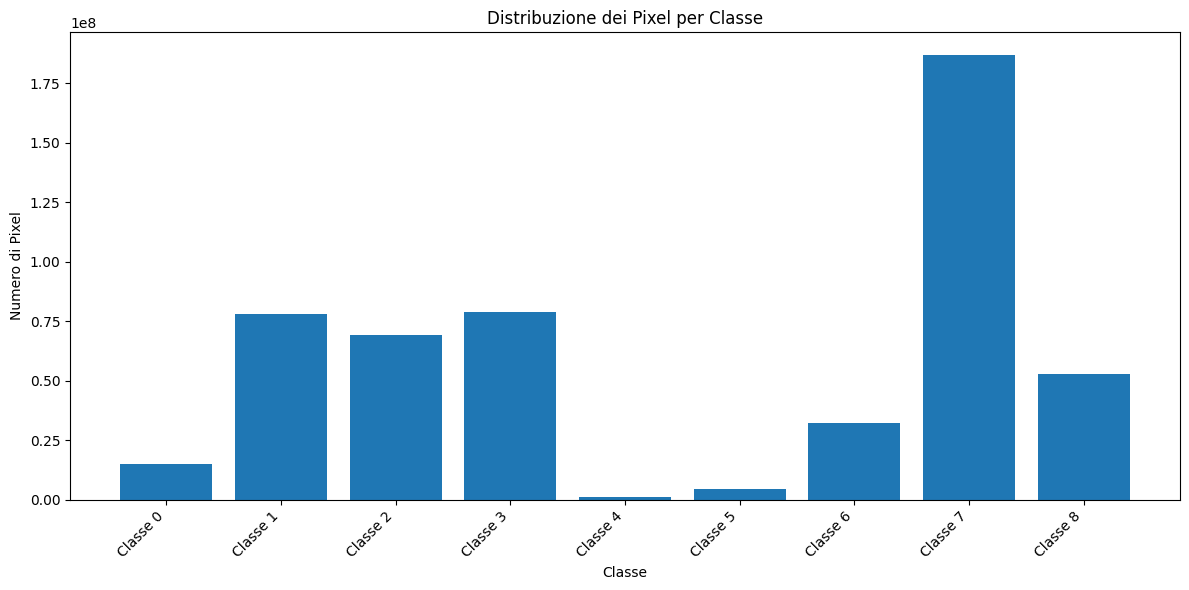





ANALISI 2: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + AUMENTATO)
Dataset originale: 931 campioni
Dataset aumentato: 561 campioni
Dataset di training finale: 1492 campioni totali


Analisi distribuzione classi (GPU): 100%|██████████| 24/24 [00:42<00:00,  1.75s/it]


Distribuzione delle classi nel dataset:
- Classe 'Classe 0' (0): 270463871 pixel (32.54%)
- Classe 'Classe 1' (1): 81934610 pixel (9.86%)
- Classe 'Classe 2' (2): 71448757 pixel (8.60%)
- Classe 'Classe 3' (3): 81916213 pixel (9.86%)
- Classe 'Classe 4' (4): 1964021 pixel (0.24%)
- Classe 'Classe 5' (5): 9102735 pixel (1.10%)
- Classe 'Classe 6' (6): 64927679 pixel (7.81%)
- Classe 'Classe 7' (7): 195561739 pixel (23.53%)
- Classe 'Classe 8' (8): 53807927 pixel (6.47%)


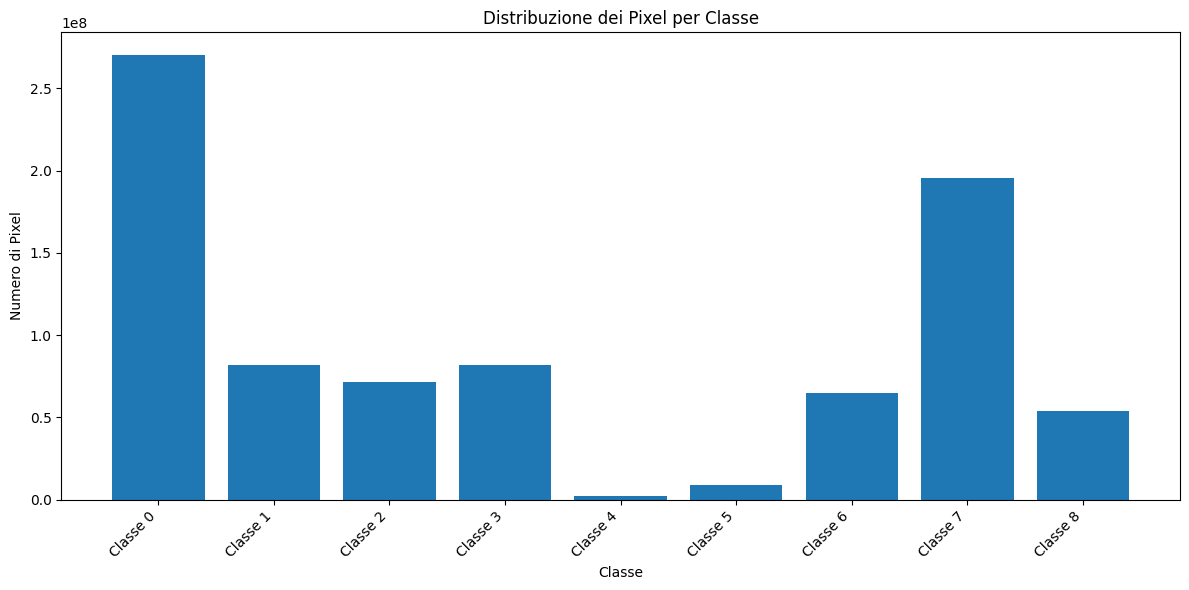

In [14]:
# %%
# ==============================================================================
# 6. ANALISI DELLA DISTRIBUZIONE POST-AUGMENTATION
# ==============================================================================
#
# OBIETTIVO:
# Verificare l'effetto della nostra data augmentation sulla distribuzione globale
# dei pixel. Ci aspettiamo di vedere un aumento significativo per le classi
# che abbiamo aumentato (4, 5, 6) e per la classe 'ignore' (0), che ora
# popola le aree irrilevanti delle maschere aumentate.

import glob
import os
import matplotlib.pyplot as plt

# Assicuriamoci che la funzione `distribution_analysis` e la classe
# `SegmentationDataset` siano definite nelle celle precedenti.

# --- 1. Analisi del dataset ORIGINALE (come baseline) ---

print("="*60)
print("ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE")
print("="*60)

# Percorsi originali (già definiti in una cella precedente)
original_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
original_sample_dirs = [d for d in original_sample_dirs if not os.path.basename(d).startswith('__')]
print(f"Trovati {len(original_sample_dirs)} campioni originali.")

original_dataset = SegmentationDataset(sample_dirs=original_sample_dirs)

# Definiamo i nomi delle classi per i grafici
class_names = [f"Classe {i}" for i in range(9)]
# Nomi più descrittivi per una migliore leggibilità
class_names_descriptive = [
    "0 (Ignore/BG)", "1 (Sky)", "2 (Rough Trail)", "3 (Smooth Trail)",
    "4 (Traversable Grass)", "5 (High Vegetation)", "6 (Low Vegetation)",
    "7 (Puddle)", "8 (Obstacle)"
]
# NOTA: La mappatura dei nomi descrittivi potrebbe non essere esatta,
# adattala in base alla documentazione del tuo dataset.
# Usiamo i nomi semplici per coerenza con il tuo codice.

distribution_analysis(original_dataset, class_names)


# --- 2. Analisi del dataset FINALE (ORIGINALE + AUMENTATO) ---

print("\n" * 3)
print("="*60)
print("ANALISI 2: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + AUMENTATO)")
print("="*60)

# Percorsi dei dati aumentati
augmented_sample_dirs = sorted([d for d in glob.glob(os.path.join(AUGMENTED_DATASET_PATH, "*")) if os.path.isdir(d)])

# Uniamo le due liste di percorsi per creare il dataset finale
final_training_dirs = original_sample_dirs + augmented_sample_dirs

print(f"Dataset originale: {len(original_sample_dirs)} campioni")
print(f"Dataset aumentato: {len(augmented_sample_dirs)} campioni")
print(f"Dataset di training finale: {len(final_training_dirs)} campioni totali")

# Creiamo l'istanza del dataset finale
final_dataset = SegmentationDataset(sample_dirs=final_training_dirs)

# Eseguiamo l'analisi della distribuzione sul dataset combinato
distribution_analysis(final_dataset, class_names)

In [15]:
# %%
# ==============================================================================
# 6. AUGMENTATION AGGRESSIVA OFFLINE (per Classi 4 e 5)
# ==============================================================================
#
# OBIETTIVO:
# Visto che le classi 4 e 5 sono ancora ignorate, aumentiamo drasticamente il
# numero di campioni che le contengono. Per ogni immagine originale con queste
# classi, generiamo N nuove varianti offline usando Albumentations, e poi
# applichiamo la nostra tecnica di mascheramento focalizzato.

import albumentations as A
import os
import numpy as np
from PIL import Image
from tqdm import tqdm
import shutil

# La funzione `create_focused_mask` è necessaria, assicurati sia definita prima.

# --- 1. Definire la pipeline di augmentation di Albumentations ---
# Queste trasformazioni introducono la varietà di cui abbiamo bisogno.
aggressive_transforms = A.Compose([
    # Trasformazioni geometriche leggere per mantenere il realismo
    A.HorizontalFlip(p=0.5),
    A.ShiftScaleRotate(
        shift_limit=0.05, 
        scale_limit=0.05, 
        rotate_limit=10, # Rotazioni leggere
        p=0.7
    ),
    A.ElasticTransform(p=0.3, alpha=10, sigma=50, alpha_affine=10),

    # Trasformazioni di colore e luminosità per simulare diverse condizioni
    A.RandomBrightnessContrast(brightness_limit=0.2, contrast_limit=0.2, p=0.7),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.5),
    A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),
])

def generate_aggressive_offline_augmentations(
    original_dataset_path: str,
    output_path: str,
    classes_to_multiply: list,
    n_variants_per_image: int
):
    """
    Genera N varianti per ogni immagine originale che contiene le classi target.
    """
    if os.path.exists(output_path):
        print(f"La cartella di augmentation aggressiva '{output_path}' esiste già. La svuoto.")
        shutil.rmtree(output_path)
    os.makedirs(output_path, exist_ok=True)
    print(f"Creata cartella per l'augmentation aggressiva: '{output_path}'")
    
    original_sample_dirs = [d for d in os.listdir(original_dataset_path) if os.path.isdir(os.path.join(original_dataset_path, d))]
    
    total_generated = 0
    
    print(f"Avvio generazione di {n_variants_per_image} varianti per le classi {classes_to_multiply}...")
    
    for original_id in tqdm(original_sample_dirs, desc="Scansione immagini originali"):
        sample_path = os.path.join(original_dataset_path, original_id)
        mask_path = os.path.join(sample_path, 'labels.png')
        img_path = os.path.join(sample_path, 'rgb.jpg')
        
        try:
            original_mask_pil = Image.open(mask_path)
            original_palette = original_mask_pil.getpalette()
            original_mask_np = np.array(original_mask_pil)
            original_image_np = np.array(Image.open(img_path))
        except Exception:
            continue
            
        # Controlla se la maschera contiene una delle classi che vogliamo moltiplicare
        target_class_present = next((cls for cls in classes_to_multiply if np.any(original_mask_np == cls)), None)

        if target_class_present is not None:
            # Trovata! Ora generiamo N varianti per questa immagine.
            for j in range(n_variants_per_image):
                # 1. Applica augmentation a immagine e maschera
                augmented = aggressive_transforms(image=original_image_np, mask=original_mask_np)
                aug_image_np = augmented['image']
                aug_mask_np = augmented['mask']
                
                # 2. Applica il mascheramento focalizzato alla maschera *già aumentata*
                focused_aug_mask_np = create_focused_mask(
                    mask=aug_mask_np,
                    target_class=target_class_present,
                    distance_threshold=30 # Puoi usare la stessa soglia di prima
                )
                
                # 3. Salva i nuovi file
                new_sample_name = f"{original_id}_variant{j}_aug_class{target_class_present}"
                new_sample_dir = os.path.join(output_path, new_sample_name)
                os.makedirs(new_sample_dir, exist_ok=True)
                
                # Salva l'immagine aumentata
                Image.fromarray(aug_image_np).save(os.path.join(new_sample_dir, 'rgb.jpg'))
                
                # Salva la maschera aumentata e focalizzata con la palette corretta
                mask_img_to_save = Image.fromarray(focused_aug_mask_np.astype(np.uint8), mode='P')
                mask_img_to_save.putpalette(original_palette)
                mask_img_to_save.save(os.path.join(new_sample_dir, 'labels.png'))
                
                total_generated += 1

    print("-" * 50)
    print("Generazione aggressiva completata.")
    print(f"Creati {total_generated} nuovi campioni diversificati.")
    print("-" * 50)


# --- ESECUZIONE DELLA PIPELINE ---

# Definiamo una NUOVA cartella per questa augmentation
AGGRESSIVE_AUG_PATH = "../../dataset/training/augmented_aggressive"
# Classi che hanno più bisogno di aiuto
CLASSES_TO_MULTIPLY = [4, 5] 
# Quante nuove versioni creare per ogni immagine che contiene una classe target
N_VARIANTS_PER_IMAGE = 10 

# Esegui la funzione usando il percorso del dataset originale come sorgente
generate_aggressive_offline_augmentations(
    original_dataset_path=DATASET_PATH, # La tua variabile con il percorso originale
    output_path=AGGRESSIVE_AUG_PATH,
    classes_to_multiply=CLASSES_TO_MULTIPLY,
    n_variants_per_image=N_VARIANTS_PER_IMAGE
)

c:\Users\Altair\AppData\Local\Programs\Python\Python313\Lib\site-packages\albumentations\core\validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
C:\Users\Altair\AppData\Local\Temp\ipykernel_13268\1977104190.py:32: UserWarning: Argument(s) 'alpha_affine' are not valid for transform ElasticTransform
  A.ElasticTransform(p=0.3, alpha=10, sigma=50, alpha_affine=10),
C:\Users\Altair\AppData\Local\Temp\ipykernel_13268\1977104190.py:37: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(10.0, 50.0), p=0.3),


Creata cartella per l'augmentation aggressiva: '../../dataset/training/augmented_aggressive'
Avvio generazione di 10 varianti per le classi [4, 5]...


Scansione immagini originali: 100%|██████████| 931/931 [02:55<00:00,  5.30it/s] 

--------------------------------------------------
Generazione aggressiva completata.
Creati 1960 nuovi campioni diversificati.
--------------------------------------------------


In [17]:
import torch
import matplotlib.pyplot as plt

# Assicurati che le altre funzioni come calculate_class_distribution_gpu
# e le variabili come 'device' siano definite.

def distribution_analysis(full_dataset, class_names):
  """
  Analizza e visualizza la distribuzione delle classi nel dataset.
  - Stampa la distribuzione completa (con classe 0).
  - Stampa la distribuzione normalizzata (senza classe 0).
  - Mostra un grafico a barre senza la classe 0.
  """
  # 1. Calcoliamo la distribuzione su tutte le classi
  distribution = calculate_class_distribution_gpu(full_dataset, device)

  # 2. Stampa della distribuzione COMPLETA (con Classe 0)
  total_pixels = distribution.sum()
  print("\n--- Distribuzione Completa (con Classe 0 'Ignore/BG') ---")
  if total_pixels > 0:
    for i, count in enumerate(distribution):
      percentage = 100 * count.float() / total_pixels
      print(f"- {class_names[i]}: {count} pixel ({percentage:.2f}%)")
  else:
    print("Nessun pixel trovato nel dataset.")

  # 3. Stampa della distribuzione NORMALIZZATA (senza Classe 0)
  print("\n--- Distribuzione Normalizzata (solo classi di interesse, senza Classe 0) ---")
  # Calcoliamo il nuovo totale escludendo la classe 0
  distribution_without_zero = distribution[1:]
  total_pixels_without_zero = distribution_without_zero.sum()

  if total_pixels_without_zero > 0:
    # Partiamo da i=1 per saltare la classe 0
    for i in range(1, len(distribution)):
      count = distribution[i]
      percentage = 100 * count.float() / total_pixels_without_zero
      print(f"- {class_names[i]}: {count} pixel ({percentage:.2f}%)")
  else:
    print("Nessun pixel trovato per le classi di interesse (1-8).")


  # 4. Visualizzazione del grafico (SENZA Classe 0)
  plt.figure(figsize=(12, 6))
  
  # Usiamo i dati e i nomi delle classi a partire dal secondo elemento (indice 1)
  class_names_for_plot = class_names[1:]
  distribution_for_plot = distribution.numpy()[1:]
  
  plt.bar(class_names_for_plot, distribution_for_plot)
  
  plt.xlabel("Classe")
  plt.ylabel("Numero di Pixel")
  plt.title("Distribuzione dei Pixel per Classe (esclusa Classe 0)")
  plt.xticks(rotation=45, ha="right")
  plt.tight_layout()
  plt.show()

ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE
ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE


Analisi distribuzione classi (GPU): 100%|██████████| 15/15 [00:14<00:00,  1.03it/s]


--- Distribuzione Completa (con Classe 0 'Ignore/BG') ---
- Classe 0: 14837133 pixel (2.86%)
- Classe 1: 78010390 pixel (15.04%)
- Classe 2: 69291002 pixel (13.36%)
- Classe 3: 78813041 pixel (15.20%)
- Classe 4: 954359 pixel (0.18%)
- Classe 5: 4489219 pixel (0.87%)
- Classe 6: 32365180 pixel (6.24%)
- Classe 7: 187016896 pixel (36.06%)
- Classe 8: 52841916 pixel (10.19%)

--- Distribuzione Normalizzata (solo classi di interesse, senza Classe 0) ---
- Classe 1: 78010390 pixel (15.48%)
- Classe 2: 69291002 pixel (13.75%)
- Classe 3: 78813041 pixel (15.64%)
- Classe 4: 954359 pixel (0.19%)
- Classe 5: 4489219 pixel (0.89%)
- Classe 6: 32365180 pixel (6.42%)
- Classe 7: 187016896 pixel (37.12%)
- Classe 8: 52841916 pixel (10.49%)


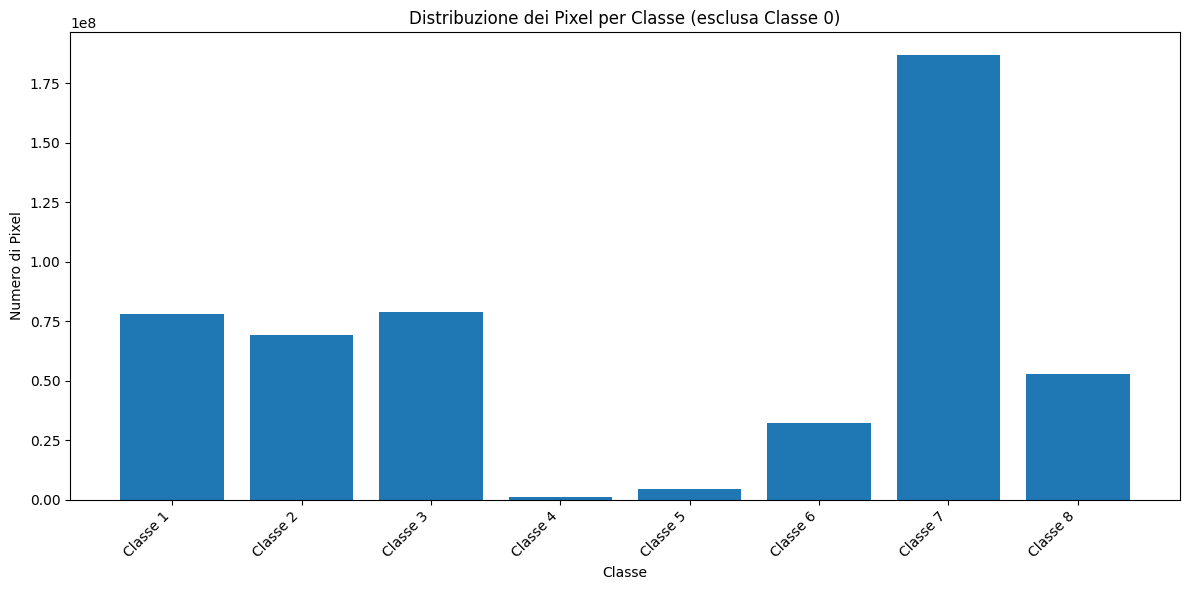





ANALISI 2: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + IGNORE AUMENTATO)


Analisi distribuzione classi (GPU): 100%|██████████| 24/24 [00:20<00:00,  1.14it/s]


--- Distribuzione Completa (con Classe 0 'Ignore/BG') ---
- Classe 0: 270463871 pixel (32.54%)
- Classe 1: 81934610 pixel (9.86%)
- Classe 2: 71448757 pixel (8.60%)
- Classe 3: 81916213 pixel (9.86%)
- Classe 4: 1964021 pixel (0.24%)
- Classe 5: 9102735 pixel (1.10%)
- Classe 6: 64927679 pixel (7.81%)
- Classe 7: 195561739 pixel (23.53%)
- Classe 8: 53807927 pixel (6.47%)

--- Distribuzione Normalizzata (solo classi di interesse, senza Classe 0) ---
- Classe 1: 81934610 pixel (14.61%)
- Classe 2: 71448757 pixel (12.74%)
- Classe 3: 81916213 pixel (14.61%)
- Classe 4: 1964021 pixel (0.35%)
- Classe 5: 9102735 pixel (1.62%)
- Classe 6: 64927679 pixel (11.58%)
- Classe 7: 195561739 pixel (34.88%)
- Classe 8: 53807927 pixel (9.60%)


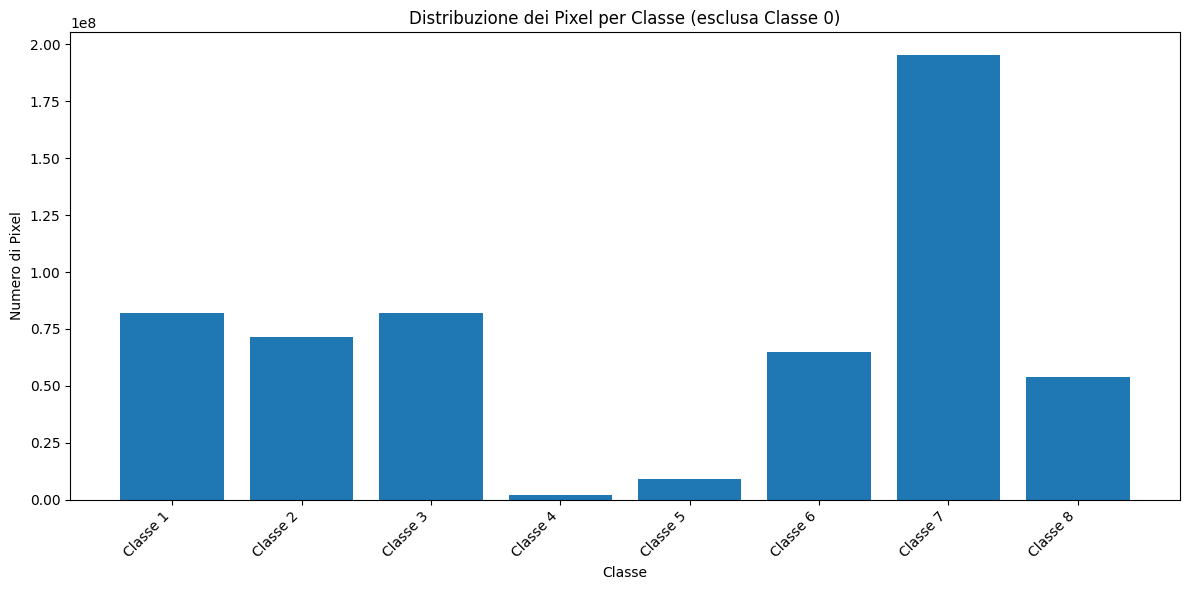





ANALISI 3: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + IGNORE + AGGRESSIVE)


Analisi distribuzione classi (GPU): 100%|██████████| 33/33 [00:27<00:00,  1.18it/s]


--- Distribuzione Completa (con Classe 0 'Ignore/BG') ---
- Classe 0: 526090609 pixel (46.00%)
- Classe 1: 85858830 pixel (7.51%)
- Classe 2: 73606512 pixel (6.44%)
- Classe 3: 85019385 pixel (7.43%)
- Classe 4: 2973683 pixel (0.26%)
- Classe 5: 13716251 pixel (1.20%)
- Classe 6: 97490178 pixel (8.52%)
- Classe 7: 204106582 pixel (17.85%)
- Classe 8: 54773938 pixel (4.79%)

--- Distribuzione Normalizzata (solo classi di interesse, senza Classe 0) ---
- Classe 1: 85858830 pixel (13.90%)
- Classe 2: 73606512 pixel (11.92%)
- Classe 3: 85019385 pixel (13.77%)
- Classe 4: 2973683 pixel (0.48%)
- Classe 5: 13716251 pixel (2.22%)
- Classe 6: 97490178 pixel (15.79%)
- Classe 7: 204106582 pixel (33.05%)
- Classe 8: 54773938 pixel (8.87%)


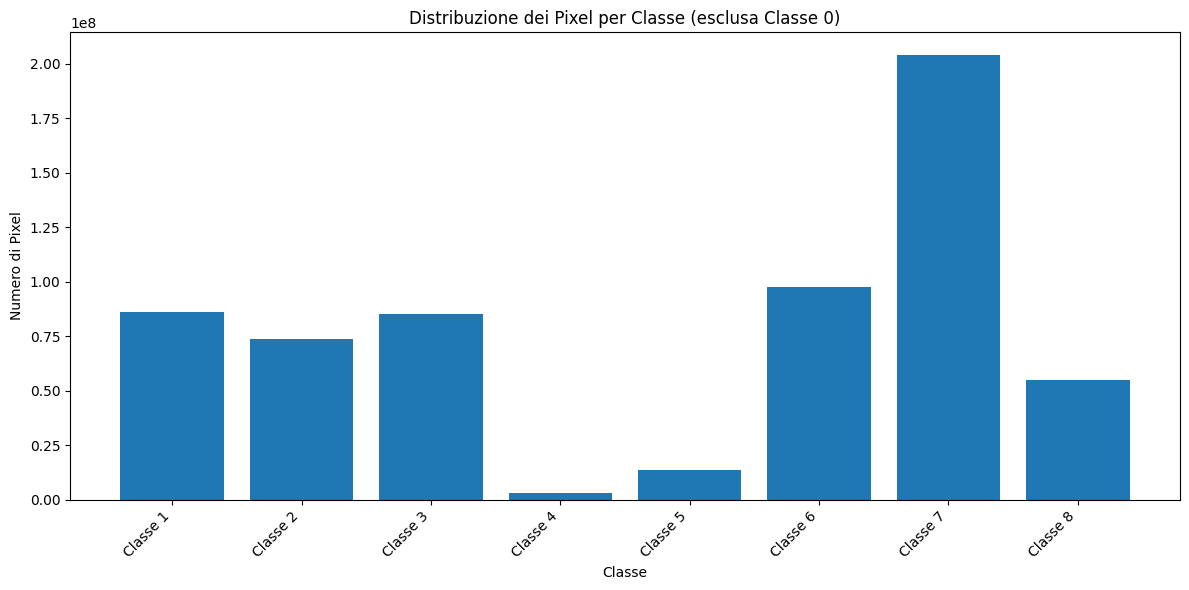

In [18]:
# %%
# ==============================================================================
# 6. ANALISI DELLA DISTRIBUZIONE POST-AUGMENTATION
# ==============================================================================
#
# OBIETTIVO:
# Verificare l'effetto della nostra data augmentation sulla distribuzione globale
# dei pixel. Ci aspettiamo di vedere un aumento significativo per le classi
# che abbiamo aumentato (4, 5, 6) e per la classe 'ignore' (0), che ora
# popola le aree irrilevanti delle maschere aumentate.

import glob
import os
import matplotlib.pyplot as plt

# Assicuriamoci che la funzione `distribution_analysis` e la classe
# `SegmentationDataset` siano definite nelle celle precedenti.

# --- 1. Analisi del dataset ORIGINALE (come baseline) ---

# Percorsi originali (già definiti in una cella precedente)
original_sample_dirs = sorted([d for d in glob.glob(os.path.join(DATASET_PATH, "*")) if os.path.isdir(d)])
original_sample_dirs = [d for d in original_sample_dirs if not os.path.basename(d).startswith('__')]

# Percorsi dei dati aumentati
augmented_sample_dirs = sorted([d for d in glob.glob(os.path.join(AUGMENTED_DATASET_PATH, "*")) if os.path.isdir(d)])

# Uniamo le due liste di percorsi per creare il dataset finale
ign_aug_training_dirs = original_sample_dirs + augmented_sample_dirs

# Uniamo le due liste di percorsi per creare il dataset finale
final_training_dirs = ign_aug_training_dirs + augmented_sample_dirs


# Definiamo i nomi delle classi per i grafici
# Nomi più descrittivi per una migliore leggibilità
class_names_descriptive = []
for idx in range(9):
    class_names_descriptive.append(f"Classe {idx}")

# --- 1. Analisi del dataset ORIGINALE ---
print("="*60)
print("ANALISI 1: DISTRIBUZIONE SUL DATASET ORIGINALE")
print("="*60)
original_dataset = SegmentationDataset(sample_dirs=original_sample_dirs)

# Passiamo i nomi descrittivi per un output più chiaro
distribution_analysis(original_dataset, class_names_descriptive)


# --- 2. Analisi del dataset FINALE (ORIGINALE + IGNORE AUMENTATO) ---
print("\n" * 3)
print("="*60)
print("ANALISI 2: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + IGNORE AUMENTATO)")
print("="*60)
final_dataset_ign = SegmentationDataset(sample_dirs=ign_aug_training_dirs)

# Passiamo i nomi descrittivi anche qui
distribution_analysis(final_dataset_ign, class_names_descriptive)


# --- 3. Analisi del dataset FINALE (ORIGINALE + IGNORE AUMENTATO + AGGR AUGMENTATO) ---
print("\n" * 3)
print("="*60)
print("ANALISI 3: DISTRIBUZIONE SUL DATASET FINALE (ORIGINALE + IGNORE + AGGRESSIVE)")
print("="*60)
final_dataset_full = SegmentationDataset(sample_dirs=final_training_dirs)

# E anche qui
distribution_analysis(final_dataset_full, class_names_descriptive)

In [20]:
import torch
from torch.utils.data import DataLoader
import numpy as np
from tqdm import tqdm

def compute_dataset_mean(dataset, batch_size=16, num_workers=0):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    mean = 0.0
    n_pixels = 0

    for images, _ in tqdm(loader, desc="Calcolo media dataset"):
        images = images.float() / 255.0  # Normalizzazione se non è già fatta
        b, c, h, w = images.shape
        mean += images.sum(dim=[0, 2, 3])
        n_pixels += b * h * w

    mean = mean / n_pixels
    return mean


def compute_dataset_std(dataset, mean, batch_size=16, num_workers=0):
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    std = 0.0
    n_pixels = 0

    for images, _ in tqdm(loader, desc="Calcolo std dataset"):
        images = images.float() / 255.0
        b, c, h, w = images.shape
        std += ((images - mean[None, :, None, None]) ** 2).sum(dim=[0, 2, 3])
        n_pixels += b * h * w

    std = torch.sqrt(std / n_pixels)
    return std


mean = compute_dataset_mean(final_dataset_full)
print("Media del dataset:", mean)

std = compute_dataset_std(final_dataset_full, mean)
print("Deviazione standard del dataset:", std)


Calcolo media dataset: 100%|██████████| 129/129 [00:28<00:00,  4.54it/s]


Media del dataset: tensor([0.0017, 0.0018, 0.0017])


Calcolo std dataset: 100%|██████████| 129/129 [00:34<00:00,  3.76it/s]

Deviazione standard del dataset: tensor([0.0010, 0.0010, 0.0010])


In [22]:
import os
import glob
import numpy as np
from PIL import Image
from tqdm import tqdm

# =============================================================================
# CONFIGURAZIONE
# =============================================================================
# Assicurati che questo percorso punti alla cartella 'train' che contiene
# tutte le sottocartelle dei campioni (0000, 0001, ecc.)
DATASET_PATH = "../../dataset/training/train" # Modifica se necessario

# =============================================================================
# FUNZIONE DI ANALISI
# =============================================================================
def find_unique_colors(dataset_path: str) -> np.ndarray:
    """
    Scansiona tutte le maschere in un dataset per trovare tutti i colori RGB unici.

    Args:
        dataset_path (str): Percorso alla directory principale del dataset.

    Returns:
        np.ndarray: Un array NumPy di colori unici, dove ogni riga è un colore [R, G, B].
    """
    print(f"Inizio scansione del dataset in: {dataset_path}")
    
    # Trova tutti i percorsi alle maschere
    mask_paths = glob.glob(os.path.join(dataset_path, "*", "labels.png"))
    [d for d in original_sample_dirs if not os.path.basename(d).startswith('__')]
    
    if not mask_paths:
        raise FileNotFoundError(f"Nessuna maschera 'labels.png' trovata nel percorso specificato.")
        
    print(f"Trovate {len(mask_paths)} maschere da analizzare.")
    
    # Usiamo un set per memorizzare i colori unici in modo efficiente,
    # salvandoli come tuple perché non possiamo mettere array in un set.
    unique_colors_set = set()

    for mask_path in tqdm(mask_paths, desc="Analisi Maschere"):
        try:
            # Apriamo l'immagine e la convertiamo in RGB per essere sicuri
            mask_img = Image.open(mask_path).convert("RGB")
            mask_np = np.array(mask_img)
            
            # Riformattiamo l'array in una lista di pixel (H*W, 3)
            # e poi troviamo i colori unici solo in questa immagine
            pixels = mask_np.reshape(-1, 3)
            unique_in_image = np.unique(pixels, axis=0)
            
            # Aggiungiamo i nuovi colori trovati al nostro set globale
            for color in unique_in_image:
                unique_colors_set.add(tuple(color))
                
        except Exception as e:
            print(f"Errore durante l'elaborazione di {mask_path}: {e}")
            
    # Convertiamo il set di tuple in un array NumPy ordinato per una migliore leggibilità
    unique_colors_array = np.array(sorted(list(unique_colors_set)))
    
    return unique_colors_array

# =============================================================================
# ESECUZIONE
# =============================================================================
try:
    # Esegui la funzione
    unique_colors = find_unique_colors(DATASET_PATH)
    
    # Stampa i risultati
    print("\n========================================================")
    print("ANALISI COMPLETATA: Colori RGB unici trovati nel dataset:")
    print("========================================================")
    
    if unique_colors.size > 0:
        for i, color in enumerate(unique_colors):
            print(f"Colore {i+1}: {tuple(color)}")
    else:
        print("Nessun colore trovato. Controlla i percorsi e il formato dei file.")
        
except FileNotFoundError as e:
    print(e)

Inizio scansione del dataset in: ../../dataset/training/train
Trovate 931 maschere da analizzare.


Analisi Maschere: 100%|██████████| 931/931 [05:58<00:00,  2.60it/s]


ANALISI COMPLETATA: Colori RGB unici trovati nel dataset:
Colore 1: (np.uint8(0), np.uint8(160), np.uint8(0))
Colore 2: (np.uint8(1), np.uint8(88), np.uint8(255))
Colore 3: (np.uint8(40), np.uint8(80), np.uint8(0))
Colore 4: (np.uint8(128), np.uint8(255), np.uint8(0))
Colore 5: (np.uint8(156), np.uint8(76), np.uint8(30))
Colore 6: (np.uint8(178), np.uint8(176), np.uint8(153))
Colore 7: (np.uint8(255), np.uint8(0), np.uint8(0))
Colore 8: (np.uint8(255), np.uint8(0), np.uint8(128))
Colore 9: (np.uint8(255), np.uint8(255), np.uint8(255))


In [25]:
import os, glob, numpy as np
from PIL import Image
from collections import Counter

ROOTS = [
    "../../dataset/training/train",
    "../../dataset/training/augmented",
    "../../dataset/training/augmented_aggressive",
]

bad   = []           # maschere sbagliate
stats = Counter()    # distribuzione max value

for root in ROOTS:
    for mask_path in glob.glob(os.path.join(root, "*", "labels.png")):
        arr = np.asarray(Image.open(mask_path))
        vmax = arr.max()
        stats[vmax] += 1
        if vmax > 8:          # oppure arr.ndim == 3
            bad.append(mask_path)

print("Distribuzione valori massimi:", stats.most_common(10))
print("Maschere fuori range:", len(bad))
if bad[:5]: print("Esempi:", bad[:5])


Distribuzione valori massimi: [(np.uint8(8), 1585), (np.uint8(7), 1315), (np.uint8(4), 257), (np.uint8(5), 167), (np.uint8(6), 128)]
Maschere fuori range: 0
